# Steel Column
**AISC 360-22 (LRFD or ASD) · ASCE 7-22 load combinations**

W, rectangular HSS, or round HSS column with axial load, end moments about both axes,
load eccentricity, and uniform lateral load along the height. Checks compression
(flexural, torsional, and slender-element buckling), flexure with Cb from the moment
diagram, H1.1 interaction with optional nonsway B1 amplification, and shear, with optional
auto-selection of the lightest W shape.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_ace3f170d5")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build ace3f170d5)")

structcalc 0.1.0 ready (build ace3f170d5)


In [2]:
#@title 1. Section and material
section = "W10X49"  #@param {type:"string"}
Fy = 50.0  #@param {type:"number"}
method = "LRFD"  #@param ["LRFD", "ASD"]
auto_select = False  #@param {type:"boolean"}
depth_filter = ""  #@param ["", "8", "10", "12", "14"]
#@markdown Section examples: `W10X33`, `HSS6X6X3/8`, `HSS6.625X0.280`. For HSS use Fy = 50 ksi (A500 Gr. C) or 46 ksi (Gr. B rectangular), 42 ksi (Gr. B round).

In [3]:
#@title 2. Geometry (ft)
H = 14.0  #@param {type:"number"}
Lcx = 14.0  #@param {type:"number"}
Lcy = 14.0  #@param {type:"number"}
Lcz = 14.0  #@param {type:"number"}
Lb = 14.0  #@param {type:"number"}
#@markdown Lcx, Lcy = effective lengths K*L for buckling about x and y. Lcz = torsional buckling length. Lb = unbraced length of the compression flange for lateral-torsional buckling.

In [4]:
#@title 3. Service loads by case
#@markdown Axial P in **kip** (+ compression). End moments in **kip-ft**: equal values at top and bottom = single curvature, opposite signs = double curvature.
P_D = 60.0  #@param {type:"number"}
P_L = 80.0  #@param {type:"number"}
P_Lr = 0.0  #@param {type:"number"}
P_S = 0.0  #@param {type:"number"}
P_W = 0.0  #@param {type:"number"}
P_E = 0.0  #@param {type:"number"}
#@markdown Strong-axis end moments (**kip-ft**), format `top, bottom` per case:
Mx_D = "0, 0"  #@param {type:"string"}
Mx_L = "0, 0"  #@param {type:"string"}
Mx_W = "0, 0"  #@param {type:"string"}
Mx_E = "0, 0"  #@param {type:"string"}
#@markdown Weak-axis end moments (**kip-ft**), format `top, bottom` per case:
My_D = "0, 0"  #@param {type:"string"}
My_L = "0, 0"  #@param {type:"string"}
My_W = "0, 0"  #@param {type:"string"}
My_E = "0, 0"  #@param {type:"string"}
#@markdown Eccentricity of the axial load at the top (in): ex makes strong-axis moment, ey makes weak-axis moment.
ex = 6.0  #@param {type:"number"}
ey = 0.0  #@param {type:"number"}
#@markdown Uniform lateral wind load along the height (plf) causing strong-axis (wx) or weak-axis (wy) bending:
wx_W = 0.0  #@param {type:"number"}
wy_W = 0.0  #@param {type:"number"}
self_weight = True  #@param {type:"boolean"}
amplify_B1 = True  #@param {type:"boolean"}

In [5]:
#@title 4. Calculate
from structcalc.calcs import steel_column

def _pair(s):
    a = [float(x) for x in str(s).replace(";", ",").split(",") if x.strip()]
    return (a + [0.0, 0.0])[:2]

case_loads = {}
for c, P in {"D": P_D, "L": P_L, "Lr": P_Lr, "S": P_S, "W": P_W, "E": P_E}.items():
    case_loads[c] = {"P": P}
for c, s in {"D": Mx_D, "L": Mx_L, "W": Mx_W, "E": Mx_E}.items():
    t, b = _pair(s)
    case_loads[c].update(Mx_top=t, Mx_bot=b)
for c, s in {"D": My_D, "L": My_L, "W": My_W, "E": My_E}.items():
    t, b = _pair(s)
    case_loads[c].update(My_top=t, My_bot=b)

out = steel_column.run(
    section=section, auto_select=auto_select, depth_filter=depth_filter,
    Fy=Fy, method=method, H=H, Lcx=Lcx, Lcy=Lcy, Lcz=Lcz, Lb=Lb,
    case_loads=case_loads, ex=ex, ey=ey,
    wx={"W": wx_W / 1000}, wy={"W": wy_W / 1000},
    self_weight=self_weight, amplify_B1=amplify_B1,
)
out["report"].show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


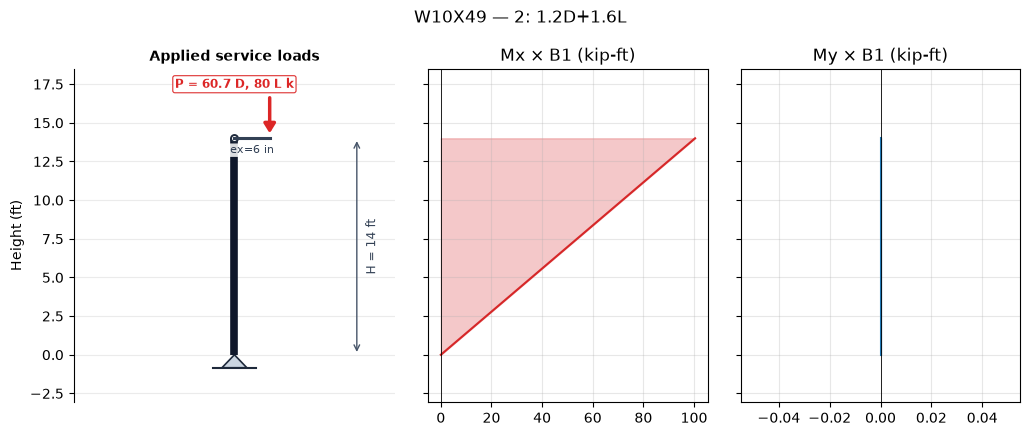

In [6]:
#@title 5. Applied loads and amplified moment diagrams (governing combination)
fig = steel_column.plot(out)

In [7]:
#@title 6. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html(f"steel_column_{out['section']['name']}.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass